<a href="https://colab.research.google.com/github/David-NNdungu/econ5200-problem-set-3/blob/main/Econ_5200_PS3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 5200 PS3 — The Rollout That Looked Like It Worked

**ECON 5200 · Causal Machine Learning & Applied Analytics**

I examine what the agency’s staggered-rollout estimate measures and how its inference changes when I account for assignment at the board level.


## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from IPython.display import display
from pathlib import Path

SEED = 42
pd.set_option("display.precision", 4)
Path("src").mkdir(exist_ok=True)

## Phase 1: The Canonical Case, Already In Your Hands (15 pts)

### Step 1.1: Carry the replication over

In [2]:
# Card & Krueger (1994), from David Card's own archive
import io
import re
import urllib.request
import zipfile

raw = urllib.request.urlopen(
    "https://davidcard.berkeley.edu/data_sets/njmin.zip", timeout=60).read()
z = zipfile.ZipFile(io.BytesIO(raw))

# public.dat is fixed-width numbers; the codebook supplies a name for each column
names = re.findall(r"^([A-Z][A-Z0-9_]+)\s+\d+\s+\d+\s+\d",
                   z.read("codebook").decode("latin-1"), re.M)
ck = pd.read_csv(io.BytesIO(z.read("public.dat")), sep=r"\s+", header=None,
                 names=names, na_values=["."])

# Full-time-equivalent employment, Card & Krueger's outcome: full-timers, managers and
# half of part-timers, in each wave (a 2 at the end of a name marks the second wave)
ck["fte_before"] = ck["EMPFT"] + ck["NMGRS"] + 0.5 * ck["EMPPT"]
ck["fte_after"] = ck["EMPFT2"] + ck["NMGRS2"] + 0.5 * ck["EMPPT2"]

print(f"{len(ck)} restaurants: {int((ck.STATE == 1).sum())} NJ, "
      f"{int((ck.STATE == 0).sum())} PA")
# The two-by-two, by hand: mean employment by state, before and after
means_by_state = ck.groupby("STATE")[["fte_before", "fte_after"]].mean()
nj, pa = means_by_state.loc[1], means_by_state.loc[0]    # STATE is 1 for New Jersey, 0 for Pennsylvania

did = (nj.fte_after - nj.fte_before) - (pa.fte_after - pa.fte_before)

print(f"{'':<12}{'before':>9}{'after':>9}{'change':>9}")
print("-" * 39)
print(f"{'NJ (treated)':<12}{nj.fte_before:>9.2f}{nj.fte_after:>9.2f}"
      f"{nj.fte_after - nj.fte_before:>9.2f}")
print(f"{'PA (control)':<12}{pa.fte_before:>9.2f}{pa.fte_after:>9.2f}"
      f"{pa.fte_after - pa.fte_before:>9.2f}")
print("-" * 39)
print(f"{'DiD':<12}{'':>18}{did:>9.2f}")
assert round(did, 2) == 2.75

410 restaurants: 331 NJ, 79 PA
               before    after   change
---------------------------------------
NJ (treated)    20.44    21.03     0.59
PA (control)    23.33    21.17    -2.17
---------------------------------------
DiD                                2.75


> **Checkpoint:** the two-by-two is **+2.75 FTE** to two decimal places. If it is not, your FTE construction or your wave assignment is wrong; fix it before anything else.

### Step 1.2: The same number from a regression

In [3]:
ck_long = ck.melt(id_vars=["STATE"], value_vars=["fte_before", "fte_after"],
                  var_name="wave", value_name="fte")
ck_long["post"] = ck_long["wave"].eq("fte_after").astype(int)
ck_fit = smf.ols("fte ~ STATE * post", data=ck_long).fit()
display(ck_long.head())
display(ck_fit.params.rename("coefficient"))
assert np.isclose(ck_fit.params["STATE:post"], did)

,STATE,wave,fte,post
0,0,fte_before,40.50,0
1,0,fte_before,13.75,0
2,0,fte_before,8.50,0
3,0,fte_before,34.00,0
4,0,fte_before,24.00,0


,coefficient
Intercept,23.3312
STATE,-2.8918
post,-2.1656
STATE:post,2.7536


The interaction reproduces the two-by-two estimate of +2.75 full-time-equivalent jobs per restaurant. The `STATE` coefficient is the initial NJ–PA gap, while the `post` coefficient is the before-to-after change in Pennsylvania. The former can reflect pre-existing differences between states. The latter measures the change in a state where the minimum wage stayed fixed, so it can reflect other changes over time.

## Phase 2: Why Their Design Fails (35 pts)

### Step 2.1: Build their panel, and reproduce their number (20 pts)

In [4]:
NEVER = 10**9
YEARS = np.arange(12)
ADOPTION = [2, 2, 2, 3, 4, 5, 5, NEVER]
COUNTIES_PER_BOARD = 5
ENTRY_EFFECT = 5.0
GROWTH = 0.25
POWER = 2
BOARD_SD = 0.20
COUNTY_FE_SD = 1.0
NOISE_SD = 0.15
COMMON_TREND = 0.10
rng = np.random.default_rng(SEED)

rows = []
for board, g in enumerate(ADOPTION):
    board_shock = rng.normal(0, BOARD_SD, size=len(YEARS))
    for local_county in range(COUNTIES_PER_BOARD):
        county = board * COUNTIES_PER_BOARD + local_county
        county_fe = rng.normal(0, COUNTY_FE_SD)
        noise = rng.normal(0, NOISE_SD, size=len(YEARS))
        for year in YEARS:
            treated = int(year >= g)
            effect = ENTRY_EFFECT + GROWTH * (year - g)**POWER if treated else 0.0
            y = county_fe + COMMON_TREND * year + board_shock[year] + noise[year] + effect
            rows.append((county, board, year, g, treated, effect, y))
panel = pd.DataFrame(rows, columns=["county", "board", "year", "g", "D", "effect", "y"])

formula = "y ~ D + C(county) + C(year)"
twfe_fit = smf.ols(formula, data=panel).fit()
twfe = twfe_fit.params["D"]
treated_effects = panel.loc[panel["D"].eq(1), "effect"]
truth = treated_effects.mean()
display(panel.head())
print(f"Counties: {panel.county.nunique()} | boards: {panel.board.nunique()} | years: {panel.year.nunique()}")
print(f"TWFE: {twfe:.4f} (default p = {twfe_fit.pvalues['D']:.4g})")
print(f"True ATT: {truth:.4f}; treated effect range: [{treated_effects.min():.4f}, {treated_effects.max():.4f}]")

,county,board,year,g,D,effect,y
0,0,0,0,2,0,0.00,0.2961
1,0,0,1,2,0,0.00,0.0282
2,0,0,2,2,1,5.00,5.2872
3,0,0,3,2,1,5.25,5.8595
4,0,0,4,2,1,6.00,5.9320


Counties: 40 | boards: 8 | years: 12
TWFE: 4.4635 (default p = 5.347e-20)
True ATT: 10.6598; treated effect range: [5.0000, 25.2500]


The agency's county and year fixed-effects regression gives 4.46 outcome units, against a true treated county-year average of 10.66. Under the default standard errors the coefficient looks statistically significant. The adoption calendar is shared within each board, and the effect grows with exposure, so I check both how the regression compares counties and how it measures uncertainty.

### Step 2.2: Decompose it (15 pts)

In [5]:
means = panel.groupby(["g", "year"])["y"].mean().unstack()
sizes = panel.groupby("g")["county"].nunique()
adopters = sorted(g for g in sizes.index if g != NEVER)
comparisons = []

def add_comparison(g, control, before, after, kind):
    gap = means.loc[g] - means.loc[control]
    estimate = gap.loc[after].mean() - gap.loc[before].mean()
    mass = sizes.loc[g] * sizes.loc[control] * len(before) * len(after)
    label = "Never" if control == NEVER else str(control)
    comparisons.append((g, label, kind, estimate, mass))

for i, early in enumerate(adopters):
    before = YEARS[YEARS < early]
    add_comparison(early, NEVER, before, YEARS[YEARS >= early], "Never treated")
    for late in adopters[i + 1:]:
        middle = YEARS[(YEARS >= early) & (YEARS < late)]
        after = YEARS[YEARS >= late]
        add_comparison(early, late, before, middle, "Not yet treated")
        add_comparison(late, early, middle, after, "Already treated")

bacon = pd.DataFrame(comparisons, columns=["treated", "control", "kind", "did", "mass"])
bacon["weight"] = bacon["mass"] / bacon["mass"].sum()
bacon["contribution"] = bacon["weight"] * bacon["did"]
bacon_twfe = bacon["contribution"].sum()
forbidden_share = bacon.loc[bacon["kind"].eq("Already treated"), "weight"].sum()

display(bacon.drop(columns="mass"))
display(bacon.groupby("kind")[["weight", "contribution"]].sum())
print(f"Weighted sum: {bacon_twfe:.4f} | Already-treated weight: {forbidden_share:.2%}")
assert np.isclose(bacon["weight"].sum(), 1)
assert np.isclose(bacon_twfe, twfe)
assert 0 < twfe < treated_effects.min()

,treated,control,kind,did,weight,contribution
0,2,Never,Never treated,11.9228,0.1161,1.3837
1,2,3,Not yet treated,4.8065,0.0116,0.0558
2,3,2,Already treated,2.5302,0.0522,0.1321
3,2,4,Not yet treated,5.1346,0.0232,0.1192
4,4,2,Already treated,0.5504,0.0928,0.0511
5,2,5,Not yet treated,5.1611,0.0696,0.3594
6,5,2,Already treated,-1.2646,0.2437,-0.3082
7,3,Never,Never treated,10.3257,0.0522,0.5393
8,3,4,Not yet treated,5.1377,0.0058,0.0298
9,4,3,Already treated,3.0702,0.0155,0.0475


,weight,contribution
kind,,
Already treated,0.4855,0.1024
Never treated,0.3656,3.5997
Not yet treated,0.1489,0.7614


Weighted sum: 4.4635 | Already-treated weight: 48.55%


Comparisons with already-treated controls receive 48.55% of the weight. When a later cohort adopts, a comparison with the early cohort subtracts the early cohort's ongoing gains from the later cohort's change. For example, the year-5 cohort versus the year-2 cohort gives −1.26 even though every treated county-year has a positive effect. The decomposition weights are all nonnegative, but they average two-by-two comparisons, some of which fall below the smallest true effect. The weighted sum of 4.46 matches TWFE and falls below the true treated-effect range of 5.00 to 25.25.

## Phase 3: The Estimate That Survives (40 pts)

### Step 3.1: Rebuild it correctly (15 pts)

In [6]:
def clean_att(df):
    """ATT(g, t) cells against not-yet-treated controls, and their size-weighted average."""
    out = []
    for g in sorted(df.loc[df["g"] < NEVER, "g"].unique()):
        treated = df[df["g"] == g]
        for t in range(g, df["year"].max() + 1):
            controls = df[df["g"] > t]                  # not yet treated at t
            if controls.empty:
                continue                                # nobody left to compare with
            d_tr = (treated.loc[treated["year"] == t, "y"].mean()
                    - treated.loc[treated["year"] == g - 1, "y"].mean())
            d_co = (controls.loc[controls["year"] == t, "y"].mean()
                    - controls.loc[controls["year"] == g - 1, "y"].mean())
            n = (treated["year"] == t).sum()               # treated units observed at t
            out.append({"g": g, "year": t, "e": t - g, "att": d_tr - d_co, "n": n})
    cells = pd.DataFrame(out)
    return cells, np.average(cells["att"], weights=cells["n"])

cells, clean = clean_att(panel)
true_cells = (panel.loc[panel["D"].eq(1)]
              .groupby(["g", "year"])["effect"].mean().rename("truth"))
cells = cells.join(true_cells, on=["g", "year"])
covered_truth = np.average(cells["truth"], weights=cells["n"])
assert np.isclose(covered_truth, truth)

# The ATT is a weighted sum of observed outcomes. Recover each outcome's weight.
contrast = np.zeros(len(panel))
for row in cells.itertuples():
    treated = panel["g"].eq(row.g)
    control = panel["g"].gt(row.year)
    for group, period, sign in [(treated, row.year, 1), (treated, row.g - 1, -1),
                                (control, row.year, -1), (control, row.g - 1, 1)]:
        mask = group & panel["year"].eq(period)
        contrast[mask] += sign * row.n / cells["n"].sum() / mask.sum()
assert np.isclose(contrast @ panel["y"], clean)

# Under the simulation's independent Gaussian shocks, sum the variance contributions.
weighted_panel = panel.assign(contrast=contrast)
county_weights = weighted_panel.groupby("county")["contrast"].sum()
assert np.allclose(county_weights, 0)
board_year_weights = weighted_panel.groupby(["board", "year"])["contrast"].sum()
clean_se = np.sqrt(BOARD_SD**2 * np.square(board_year_weights).sum()
                   + NOISE_SD**2 * np.square(contrast).sum())
clean_ci = clean + stats.norm.ppf([0.025, 0.975]) * clean_se
display(cells)
print(f"Clean ATT: {clean:.4f} | covered truth: {covered_truth:.4f} | TWFE: {twfe:.4f}")
print(f"Simulation-based 95% interval: [{clean_ci[0]:.4f}, {clean_ci[1]:.4f}]")

,g,year,e,att,n,truth
0,2,2,0,4.8477,15,5.00
1,2,3,1,5.2742,15,5.25
2,2,4,2,5.6613,15,6.00
3,2,5,3,6.9404,15,7.25
4,2,6,4,8.6521,15,9.00
5,2,7,5,10.7529,15,11.25
6,2,8,6,14.3018,15,14.00
7,2,9,7,16.7451,15,17.25
8,2,10,8,20.8401,15,21.00
9,2,11,9,24.8373,15,25.25


Clean ATT: 10.4790 | covered truth: 10.6598 | TWFE: 4.4635
Simulation-based 95% interval: [10.1892, 10.7687]


I compared each cohort at each post-adoption date with counties still untreated at that date, using the cohort's final pre-adoption year as the baseline. I weighted each estimate by its number of treated counties. The never-treated board gives every post-adoption cell a comparison, so the aggregate covers the full treated county-year population. It estimates 10.48 units versus 10.66 in the simulation and 4.46 from TWFE. The simulation-based interval uses the shock variances I planted and accounts for counties sharing a board-year shock and for the same observations appearing in multiple comparisons.

### Step 3.2: The assumption you cannot test (12 pts)

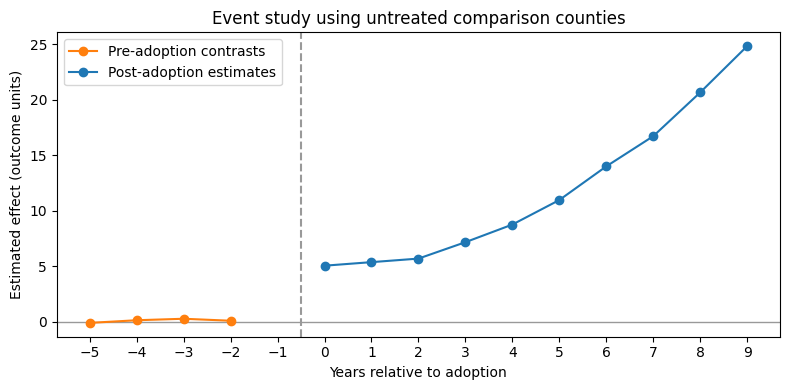

,e,att,n
0,-5,-0.1226,10
1,-4,0.1161,15
2,-3,0.2499,20
3,-2,0.0712,35
4,0,5.0364,35
5,1,5.3565,35
6,2,5.6766,35
7,3,7.1562,35
8,4,8.7462,35
9,5,10.9584,35


In [7]:
def mean_at(mask, period):
    return panel.loc[mask & panel["year"].eq(period), "y"].mean()


lead_rows = []
for g in adopters:
    baseline = g - 1
    treated = panel["g"].eq(g)
    controls = panel["g"].gt(g)
    for year in YEARS[YEARS < baseline]:
        lead = (mean_at(treated, year) - mean_at(treated, baseline)
                - mean_at(controls, year) + mean_at(controls, baseline))
        n_treated = (treated & panel["year"].eq(year)).sum()
        lead_rows.append((g, year, year - g, lead, n_treated))

leads = pd.DataFrame(lead_rows, columns=["g", "year", "e", "att", "n"])
event_cells = pd.concat([leads, cells], ignore_index=True)
event = pd.DataFrame([
    (e, np.average(group["att"], weights=group["n"]), group["n"].sum())
    for e, group in event_cells.groupby("e")
], columns=["e", "att", "n"])

fig, ax = plt.subplots(figsize=(8, 4))
ax.axhline(0, color="0.6", linewidth=1)
ax.axvline(-0.5, color="0.6", linestyle="--")
ax.plot(event.loc[event["e"].lt(-1), "e"], event.loc[event["e"].lt(-1), "att"],
        "o-", color="tab:orange", label="Pre-adoption contrasts")
ax.plot(event.loc[event["e"].ge(0), "e"], event.loc[event["e"].ge(0), "att"],
        "o-", color="tab:blue", label="Post-adoption estimates")
ax.set(xlabel="Years relative to adoption", ylabel="Estimated effect (outcome units)",
       title="Event study using untreated comparison counties")
ax.set_xticks(range(int(event["e"].min()), int(event["e"].max()) + 1))
ax.legend()
fig.tight_layout()
plt.show()
display(event)

I omit event time −1, the last year before adoption, so each coefficient measures the treated group's change relative to its comparison group from that baseline. The estimated leads are small relative to the post-adoption effects. That pattern is consistent with parallel trends before adoption, but it cannot establish how treated counties would have evolved without training. To interpret the post-adoption estimates causally, I would need to argue that untreated outcome changes would have been the same for each cohort and its comparison counties and that counties did not respond before adoption.

### Step 3.3: Inference with what you have (10 pts, plus 3 for the module)

In [8]:
iid = twfe_fit
county_clustered = smf.ols(formula, data=panel).fit(
    cov_type="cluster", cov_kwds={"groups": panel["county"]}, use_t=True
)
board_clustered = smf.ols(formula, data=panel).fit(
    cov_type="cluster", cov_kwds={"groups": panel["board"]}, use_t=True
)
inference = pd.DataFrame([
    (label, fit.params["D"], fit.bse["D"], fit.pvalues["D"])
    for label, fit in [("Default", iid), ("County", county_clustered), ("Board", board_clustered)]
], columns=["inference", "estimate", "se", "p"]).set_index("inference")
display(inference)

,estimate,se,p
inference,,,
Default,4.4635,0.4635,5.3473e-20
County,4.4635,1.0350,1.0638e-04
Board,4.4635,2.4421,1.1031e-01


The module the brief asks for: start from Lab 11's `src/did_utils.py` (`two_by_two`, `event_study`) and the notebook's `clean_att`, then add the clustered-inference wrapper and, in Phase 4, the bootstrap. Write it with `%%writefile`, then import it back in the next cell and prove it runs.

In [9]:
%%writefile src/did_toolkit.py
"""Difference-in-differences toolkit extending the Lab 11 helpers."""
from __future__ import annotations

import numpy as np
import pandas as pd

NEVER = 10 ** 9      # the cohort of a never-treated unit: later than any period


def two_by_two(df: pd.DataFrame, outcome: str, treated: str, post: str) -> float:
    """The canonical 2x2: difference of differences of the four group means."""
    g = df.groupby([treated, post])[outcome].mean()
    return (g[1, 1] - g[1, 0]) - (g[0, 1] - g[0, 0])


def att_by_cohort_period(df: pd.DataFrame, time: str, outcome: str,
                         cohort: str) -> pd.DataFrame:
    """ATT(g, t) for every cohort g and period t >= g.

    Controls are units NOT YET treated at t, never units already treated.
    The baseline is period g - 1, the last period before cohort g is treated.
    Returns one row per (g, t): the event time e = t - g, the estimate, and
    the number of treated units it rests on.
    """
    out = []
    cohorts = sorted(c for c in df[cohort].unique() if c < NEVER)
    for g in cohorts:
        tr = df[df[cohort] == g]
        for t in sorted(df.loc[df[time] >= g, time].unique()):
            co = df[df[cohort] > t]              # not yet treated at t
            if co.empty or (tr[time] == g - 1).sum() == 0:
                continue                         # no control left, or no baseline period
            d_tr = (tr.loc[tr[time] == t, outcome].mean()
                    - tr.loc[tr[time] == g - 1, outcome].mean())
            d_co = (co.loc[co[time] == t, outcome].mean()
                    - co.loc[co[time] == g - 1, outcome].mean())
            out.append({"g": g, "t": t, "e": t - g,
                        "att": d_tr - d_co, "n": int((tr[time] == t).sum())})
    return pd.DataFrame(out)


def overall_att(cells: pd.DataFrame) -> float:
    """Size-weighted average of the ATT(g, t) cells."""
    return float(np.average(cells["att"], weights=cells["n"]))


def event_study(cells: pd.DataFrame) -> pd.DataFrame:
    """Average the ATT(g, t) cells by event time e = t - g, weighted by size.

    Negative e would be pre-treatment periods. They are a diagnostic, not a
    test: estimates near zero are consistent with parallel trends and do not
    establish it.
    """
    rows = []
    for e, group in cells.groupby("e"):
        rows.append({"e": e, "att": np.average(group["att"], weights=group["n"])})
    return pd.DataFrame(rows)


def cluster_se_ratio(fit_iid, fit_clustered, param: str) -> float:
    """How many times larger the clustered standard error is than the iid one."""
    return float(fit_clustered.bse[param] / fit_iid.bse[param])


def clustered_inference(
    data: pd.DataFrame, formula: str, term: str, county: str, board: str
) -> pd.DataFrame:
    """Report iid, county-clustered and board-clustered inference on the same OLS fit."""
    import statsmodels.formula.api as smf

    model = smf.ols(formula, data=data, missing="raise")
    fits = {"Default": model.fit()}
    for label, group in [("County", county), ("Board", board)]:
        fits[label] = model.fit(
            cov_type="cluster", cov_kwds={"groups": data[group]}, use_t=True
        )
    return pd.DataFrame([
        {"inference": label, "estimate": fit.params[term],
         "se": fit.bse[term], "p": fit.pvalues[term]}
        for label, fit in fits.items()
    ]).set_index("inference")


def wild_cluster_bootstrap(
    data: pd.DataFrame, formula: str, term: str, cluster: str
) -> dict[str, float | int]:
    """Enumerate the restricted two-sided wild cluster bootstrap for a single term."""
    from itertools import product

    import statsmodels.api as sm
    import statsmodels.formula.api as smf

    model = smf.ols(formula, data=data, missing="raise")
    x = model.exog
    j = model.exog_names.index(term)
    codes, clusters = pd.factorize(data[cluster])
    if len(clusters) < 2 or (codes < 0).any():
        raise ValueError("At least two nonmissing clusters are required.")
    fit_options = {
        "cov_type": "cluster", "cov_kwds": {"groups": codes}, "use_t": True
    }
    unrestricted = model.fit(**fit_options)
    observed = float(unrestricted.tvalues[term])
    restricted = sm.OLS(model.endog, np.delete(x, j, axis=1)).fit()
    fitted, residuals = restricted.fittedvalues, restricted.resid

    t_star = []
    for signs in product((-1, 1), repeat=len(clusters)):
        y_star = fitted + np.asarray(signs)[codes] * residuals
        t_star.append(sm.OLS(y_star, x).fit(**fit_options).tvalues[j])

    magnitudes = np.abs(t_star)
    threshold = abs(observed)
    # Count numerical ties, including the all-positive and all-negative draws.
    extreme = (magnitudes > threshold) | np.isclose(
        magnitudes, threshold, rtol=1e-10, atol=1e-12
    )
    return {"t": observed, "cluster_p": float(unrestricted.pvalues[term]),
            "bootstrap_p": float(extreme.mean()), "vectors": len(t_star),
            "extreme": int(extreme.sum())}


if __name__ == "__main__":
    toy = pd.DataFrame({"treated": [0, 0, 1, 1], "post": [0, 1, 0, 1],
                        "y": [1, 2, 4, 7]})
    assert np.isclose(two_by_two(toy, "y", "treated", "post"), 2)
    print("Toolkit smoke test passed.")

Writing src/did_toolkit.py


In [10]:
import importlib
import os
import sys
sys.path.insert(0, os.path.abspath("."))
from src import did_toolkit as dt
importlib.reload(dt)

assert np.isclose(dt.two_by_two(ck_long, "fte", "STATE", "post"), did)
module_cells = dt.att_by_cohort_period(panel, "year", "y", "g")
assert np.isclose(dt.overall_att(module_cells), clean)
module_event = dt.event_study(event_cells)
assert np.array_equal(module_event["e"], event["e"])
assert np.allclose(module_event["att"], event["att"])
assert np.allclose(dt.clustered_inference(panel, formula, "D", "county", "board"), inference)
assert np.isclose(dt.cluster_se_ratio(iid, board_clustered, "D"),
                  inference.loc["Board", "se"] / inference.loc["Default", "se"])
print("Toolkit checks passed.")

Toolkit checks passed.


The coefficient is 4.46 under all three fits. Its standard error rises from 0.46 under the default fit to 1.04 when clustered by county and 2.44 when clustered by board. County clustering allows repeated outcomes from a county to be correlated, but it treats counties in the same board as independent. Board clustering matches the level of adoption and allows dependence across counties and years within a board. With only eight boards, the conventional board-clustered p-value still relies on a small number of independent groups.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts: 4 for Task 4.1, 3 for Task 4.2, 3 for Task 4.3)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The inference you cannot do by hand

In [11]:
bootstrap = dt.wild_cluster_bootstrap(panel, formula, "D", "board")
assert bootstrap["vectors"] == 2 ** panel["board"].nunique()
assert bootstrap["extreme"] % 2 == 0
assert bootstrap["extreme"] >= 2
assert np.isclose(bootstrap["cluster_p"], inference.loc["Board", "p"])
print(f"Board-clustered t: {bootstrap['t']:.4f}")
print(f"Conventional board-clustered p: {bootstrap['cluster_p']:.6f}")
print(f"Wild cluster bootstrap p: {bootstrap['bootstrap_p']:.6f}")
print(f"Extreme vectors: {bootstrap['extreme']} of {bootstrap['vectors']}")
print(f"Smallest attainable two-sided p: {2 / bootstrap['vectors']:.6f}")

Board-clustered t: 1.8277
Conventional board-clustered p: 0.110313
Wild cluster bootstrap p: 0.132812
Extreme vectors: 34 of 256
Smallest attainable two-sided p: 0.007812


The conventional board-clustered p-value is 0.1103 and the enumerated bootstrap p-value is 0.1328. At a 5% threshold, the agency's significance claim based on the default standard errors does not survive board-level inference. The two board-based methods reach the same decision. This calculation concerns the agency's TWFE coefficient.

I enumerate all 256 sign vectors, so there is no Monte Carlo error or replication count to choose. All positive signs reconstruct the observed outcome. Reversing every sign negates the treatment t-statistic under the imposed null and leaves its absolute value unchanged. At least that pair counts in the tail, so the smallest reportable two-sided p-value is 2/256, or 0.0078125.

### Task 4.2: The budget office memo

**To the legislative budget office**

The agency reported an estimated gain of 4.46 outcome units. Its method partly compares counties that just started training with counties where training was already underway. Those earlier counties were still improving, so using them as a benchmark subtracts some of the program's gains. Once I account for the rollout being assigned by regional board, the agency estimate has a bootstrap p-value of 0.133 and falls short of the 5% significance threshold.

Using only counties that had yet to start training or never started, I estimate a gain of 10.48 outcome units. The 95% interval is 10.19 to 10.77 under the shock assumptions in the simulation. That interval describes uncertainty in this simulated exercise. It gives no direct estimate of the gains the state would see from extending the program.

I would defer expansion funding on the strength of the agency's analysis alone. Before deciding on expansion, I would request a reanalysis of actual county outcomes using untreated comparisons, board-level inference, and a comparison of program benefits with costs.

### Task 4.3: The hostile read (3 pts)

**Before the review**

I omit event time −1, the last year before adoption, so each coefficient measures the treated group's change relative to its comparison group from that baseline. The estimated leads are small relative to the post-adoption effects. That pattern is consistent with parallel trends before adoption, but it cannot establish how treated counties would have evolved without training. To interpret the post-adoption estimates causally, I would need to argue that untreated outcome changes would have been the same for each cohort and its comparison counties and that counties did not respond before adoption.

**After the review**

I omit event time −1, the last year before adoption, so each lead or lag is measured relative to that baseline. The estimated leads are small relative to the post-adoption effects, but with few boards and changing cohort coverage across leads, the plot may miss meaningful pre-adoption differences. To interpret each post-adoption comparison causally, I would need to argue that the treated cohort and its available controls would have had the same average outcome change from the baseline in the absence of training. I would check the rollout records for anticipation, spillovers into comparison counties, and concurrent changes in funding or labor-market conditions. At longer exposures the estimates rely on the never-treated board as the control, so its comparability matters especially there.

| Objection | Accept or reject | Why | What I changed |
|---|---|---|---|
| After all adopting boards have begun training, a single board anchors the untreated comparison. | Accept | A change specific to that board can affect several late comparisons at once. | Named the reliance on that board at longer exposures. |
| Small leads could reflect low power or different cohorts contributing at different leads. | Accept | A small number of boards and uneven lead coverage limit what the figure can rule out. | Made both limits explicit. |
| Flat leads are enough to validate the agency's TWFE coefficient. | Reject | Parallel untreated trends would leave the already-treated control group's growing treatment effect in the comparison. | Kept the pre-trend diagnostic separate from the decomposition argument. |

### AI Transcript

Paste **both prompt versions exactly as you sent them** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date. For 5200 the transcript lives in `ai-appendix.md` in your repository; link it here.

[Phase 4 appendix](ai-appendix.md)

I put my prompts, bootstrap checks, and notes on the parallel-trends revision in the appendix. The verbatim replies still need to be added.

## Truth and headline numbers

Required, and it must stay the **last code cell**. Print every parameter you planted in the §2.1 panel (cohort adoption years, the effect's growth with exposure, the board-shock variance, the seed), each beside the name of the cell that set it; then every number that appears in the memo, each beside the name of the cell that produced it. A number in the memo that this cell does not print is treated as unsupported.

In [12]:
print("Truth and headline numbers")
print(f"Seed: {SEED} — Setup")
print(f"Periods: {YEARS.tolist()}; counties per board: {COUNTIES_PER_BOARD} — Step 2.1")
adoption_display = ["Never" if g == NEVER else int(g) for g in ADOPTION]
print(f"Adoption year by board (board 0 first): {adoption_display} — Step 2.1")
print(f"Never-treated code: {NEVER} — Step 2.1")
print(f"Effect at exposure e: {ENTRY_EFFECT} + {GROWTH} × e^{POWER} — Step 2.1")
print(f"Board-year shock SD: {BOARD_SD}; variance: {BOARD_SD**2:.4f} — Step 2.1")
print(f"County fixed-effect SD: {COUNTY_FE_SD}; idiosyncratic SD: {NOISE_SD} — Step 2.1")
print(f"Common annual trend: {COMMON_TREND} — Step 2.1")
print(f"Card–Krueger DiD: {did:+.2f} FTE — Step 1.1")
print(f"Agency TWFE: {twfe:.2f}; true ATT: {truth:.2f} — Step 2.1")
print(f"Already-treated weight: {forbidden_share:.2%} — Step 2.2")
print(f"Clean ATT: {clean:.2f}; 95% simulation interval: [{clean_ci[0]:.2f}, {clean_ci[1]:.2f}] — Step 3.1")
print(f"Board-clustered p: {bootstrap['cluster_p']:.4f} — Step 3.3 and Task 4.1")
print(f"Wild cluster bootstrap p: {bootstrap['bootstrap_p']:.3f} — Task 4.1")
print("Significance threshold: 5% — Task 4.1")

Truth and headline numbers
Seed: 42 — Setup
Periods: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]; counties per board: 5 — Step 2.1
Adoption year by board (board 0 first): [2, 2, 2, 3, 4, 5, 5, 'Never'] — Step 2.1
Never-treated code: 1000000000 — Step 2.1
Effect at exposure e: 5.0 + 0.25 × e^2 — Step 2.1
Board-year shock SD: 0.2; variance: 0.0400 — Step 2.1
County fixed-effect SD: 1.0; idiosyncratic SD: 0.15 — Step 2.1
Common annual trend: 0.1 — Step 2.1
Card–Krueger DiD: +2.75 FTE — Step 1.1
Agency TWFE: 4.46; true ATT: 10.66 — Step 2.1
Already-treated weight: 48.55% — Step 2.2
Clean ATT: 10.48; 95% simulation interval: [10.19, 10.77] — Step 3.1
Board-clustered p: 0.1103 — Step 3.3 and Task 4.1
Wild cluster bootstrap p: 0.133 — Task 4.1
Significance threshold: 5% — Task 4.1


## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; both prompt versions are in it.
- [ ] Upload the `.ipynb`, your `ai-appendix.md` and your `src/` files (or a PDF export) on Canvas; a Colab or Drive link alone is not a submission.
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 3/Econ_5200_PS3.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.